# Proj2 — Schema Linking SFT (TRL, no RapidFire AI)

Trains Qwen2.5 models with LoRA via TRL's `SFTTrainer` directly.  
Runs sequentially (one config at a time) — stable in Colab A100.

| Run | Model | LR | LoRA |
|-----|-------|----|------|
| 0 | Qwen2.5-0.5B-Instruct | 2e-5 | r=16 |
| 1 | Qwen2.5-1.5B-Instruct | 2e-5 | r=16 |

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
try_path = '/content/drive/MyDrive/schema-linker-sft-pipeline/try/'
if try_path not in sys.path:
    sys.path.append(try_path)
import paths

!pip install -q -r {paths.REPO_ROOT}/requirements.txt
!pip install -q "torchao>=0.16.0"  # fixes peft 0.19.1 compatibility in Colab

## 0. Config knobs — edit here

In [ ]:
from datetime import datetime
from pathlib import Path
from paths import LOGS_DIR, TRAIN_JSON, VAL_JSON, SCHEMAS_DIR, print_paths, require_release_data, setup

setup(chdir_try=True)
require_release_data()
print_paths()

RUN_IDS      = [0, 1]     # 0 = 0.5B, 1 = 1.5B; set [0] to run just one
NUM_EPOCHS   = 1
MAX_LENGTH   = 1024       # reduce to 512 if Colab OOMs
SCHEMA_STYLE = "minimal"  # or "full"
SEED         = 42

EXPERIMENT_NAME = f"proj2-trl-{datetime.now():%Y%m%d-%H%M}"
EXPERIMENT_DIR  = LOGS_DIR / EXPERIMENT_NAME
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
print(f"\nExperiment : {EXPERIMENT_NAME}")
print(f"Saving to  : {EXPERIMENT_DIR}")

## 1. Imports & data

In [ ]:
import gc, json, re
import torch
from datasets import Dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model, TaskType
from trl import SFTConfig, SFTTrainer

with open(TRAIN_JSON) as f: raw_train = json.load(f)
with open(VAL_JSON)   as f: raw_val   = json.load(f)
print(f"Train: {len(raw_train)} | Val: {len(raw_val)}")
print("Example keys:", list(raw_train[0].keys()))

## 2. Schema helpers & formatting

Imports from `schema_formatting.py` — uses the same `SYSTEM_PROMPT`, serializers, and `sort_schema_links` as the rapidfireai notebooks.

In [ ]:
from schema_formatting import (
    load_schema,
    serialize_schema_minimal,
    serialize_schema_full,
    SYSTEM_PROMPT,
    sort_schema_links,
)

_serialize = serialize_schema_minimal if SCHEMA_STYLE == "minimal" else serialize_schema_full


def build_text(row: dict, tokenizer) -> str:
    schema_s = _serialize(load_schema(row["db_id"]))
    user_msg = f"Database schema:\n{schema_s}\n\nQuestion: {row['question']}"
    target   = json.dumps(sort_schema_links(row["schema_links"]), ensure_ascii=False)
    messages = [
        {"role": "system",    "content": SYSTEM_PROMPT},
        {"role": "user",      "content": user_msg},
        {"role": "assistant", "content": target},
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)


def make_text_dataset(raw_data: list, tokenizer, shuffle: bool = False) -> Dataset:
    records = [{"text": build_text(row, tokenizer)} for row in raw_data]
    ds = Dataset.from_list(records)
    return ds.shuffle(seed=SEED) if shuffle else ds


print("Schema formatting loaded from schema_formatting.py. Style:", SCHEMA_STYLE)

## 3. Config catalog

In [ ]:
QWEN_05B = "Qwen/Qwen2.5-0.5B-Instruct"
QWEN_15B = "Qwen/Qwen2.5-1.5B-Instruct"

RUN_CATALOG = [
    {"run_id": 0, "model": QWEN_05B, "lr": 2e-5, "lora_r": 16, "lora_alpha": 32, "label": "0.5B | lr=2e-5 | r=16"},
    {"run_id": 1, "model": QWEN_15B, "lr": 2e-5, "lora_r": 16, "lora_alpha": 32, "label": "1.5B | lr=2e-5 | r=16"},
]

selected = [e for e in RUN_CATALOG if e["run_id"] in RUN_IDS]
if not selected:
    raise ValueError(f"RUN_IDS {RUN_IDS} matched no catalog entries")
print(f"Configs to run: {len(selected)}")
for e in selected:
    print(f"  run_id={e['run_id']}  {e['label']}")

## 4. TensorBoard

Start TensorBoard **before** training so you can watch loss curves appear in real time.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir {str(EXPERIMENT_DIR)}

## 5. Training loop

Runs each config sequentially. The cell **blocks until all runs complete** — this is intentional:  
keeping the cell active prevents Colab from killing the training process.

Checkpoints are saved to Google Drive after each run.

In [ ]:
run_results = []

for entry in selected:
    print(f"\n{'='*60}")
    print(f"  Run {entry['run_id']}: {entry['label']}")
    print(f"{'='*60}")

    run_dir  = EXPERIMENT_DIR / f"runs/{entry['run_id']}"
    ckpt_dir = run_dir / "checkpoints" / "final_checkpoint"
    run_dir.mkdir(parents=True, exist_ok=True)

    # ── 1. Tokenizer ──────────────────────────────────────────────
    print("Loading tokenizer...")
    tokenizer = AutoTokenizer.from_pretrained(entry["model"], trust_remote_code=False)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    tokenizer.model_max_length = MAX_LENGTH

    # ── 2. Datasets ───────────────────────────────────────────────
    print("Formatting datasets...")
    train_ds = make_text_dataset(raw_train, tokenizer, shuffle=True)
    val_ds   = make_text_dataset(raw_val,   tokenizer, shuffle=False)
    print(f"  train={len(train_ds)}  val={len(val_ds)}")

    # ── 3. Model ──────────────────────────────────────────────────
    print("Loading model...")
    model = AutoModelForCausalLM.from_pretrained(
        entry["model"],
        device_map="auto",
        torch_dtype=torch.bfloat16,
        use_cache=False,
    )

    # ── 4. LoRA ───────────────────────────────────────────────────
    lora_cfg = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=entry["lora_r"],
        lora_alpha=entry["lora_alpha"],
        lora_dropout=0.05,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
        bias="none",
    )
    model = get_peft_model(model, lora_cfg)
    model.enable_input_require_grads()  # required for gradient_checkpointing + PEFT
    model.print_trainable_parameters()

    # ── 5. SFTTrainer ─────────────────────────────────────────────
    sft_args = SFTConfig(
        output_dir=str(run_dir / "checkpoints"),
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=1,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=4,
        learning_rate=entry["lr"],
        lr_scheduler_type="cosine",
        warmup_ratio=0.05,
        max_grad_norm=0.3,
        weight_decay=0.01,
        logging_steps=10,
        eval_strategy="epoch",
        save_strategy="steps",
        save_steps=50,           # save mid-epoch so progress isn't lost if Colab disconnects
        save_total_limit=2,
        load_best_model_at_end=False,
        bf16=True,
        fp16=False,
        gradient_checkpointing=True,
        report_to="tensorboard",
        logging_dir=str(run_dir / "tensorboard"),
        dataset_text_field="text",
        seed=SEED,
    )

    trainer = SFTTrainer(
        model=model,
        args=sft_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        processing_class=tokenizer
    )

    print("Training...")
    trainer.train()

    # ── 6. Save final checkpoint ──────────────────────────────────
    print(f"Saving checkpoint to {ckpt_dir} ...")
    trainer.save_model(str(ckpt_dir))
    tokenizer.save_pretrained(str(ckpt_dir))
    print(f"\u2705 Saved: {ckpt_dir}")
    run_results.append({"run_id": entry["run_id"], "label": entry["label"], "ckpt": str(ckpt_dir)})

    # ── 7. Free GPU for next run ──────────────────────────────────
    del model, trainer
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    print("GPU cleared.")

print("\n" + "="*60)
print("All runs complete!")
for r in run_results:
    print(f"  run {r['run_id']} ({r['label']})  ->  {r['ckpt']}")

## 6. Checkpoint paths for main.py

Pass these to `main.py` for inference.

In [4]:
# pip install pandas

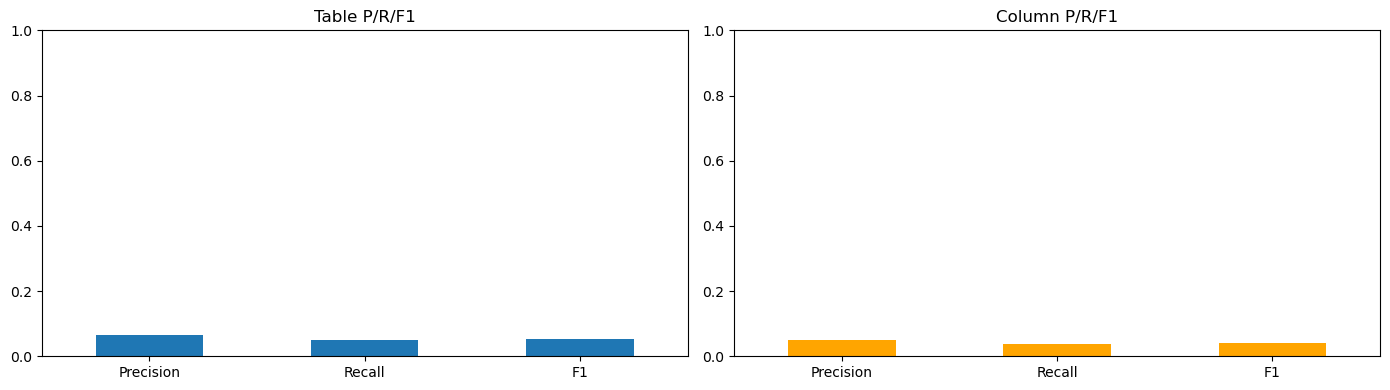

In [3]:
import pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("/Users/emilychen/code/schema-linker-sft-pipeline/per_question_run1.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Table metrics
df[["p_t", "r_t", "f1_t"]].mean().plot(kind="bar", ax=axes[0], ylim=(0,1))
axes[0].set_title("Table P/R/F1"); axes[0].set_xticklabels(["Precision", "Recall", "F1"], rotation=0)

# Column metrics
df[["p_c", "r_c", "f1_c"]].mean().plot(kind="bar", ax=axes[1], ylim=(0,1), color="orange")
axes[1].set_title("Column P/R/F1"); axes[1].set_xticklabels(["Precision", "Recall", "F1"], rotation=0)

plt.tight_layout()
plt.savefig("eval_run1.png", dpi=120)
plt.show()